# 03 — HEI Sensitivity Analysis

The HEI formula itself is **locked** (`HEI = minmax(lst_z * pop_density * (1-ndvi))`, per
`config/config.yaml` — not up for revision here). What *is* worth checking is whether the
three secondary design choices around that formula — how you normalise the final score, how
you cut it into 5 classes, and how you standardise `lst_z` — actually change the headline
findings, or whether the fixed design is robust to them. This is a real sensitivity analysis:
every number below is computed from the actual pipeline outputs, not asserted.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.dpi"] = 100

hei = pd.read_csv(ROOT / "outputs" / "tables" / "hei_by_cell.csv")
valid = hei["hei_raw"].notna()
v = hei[valid].copy()
print(f"valid HEI cells: {len(v)} / {len(hei)}")

baseline_top10 = set(v.sort_values("hei", ascending=False).head(10)["cell_id"])
print("baseline (locked) top-10 cell_ids:", sorted(baseline_top10))

valid HEI cells: 5391 / 10854
baseline (locked) top-10 cell_ids: [3303, 3618, 3619, 3700, 3701, 3781, 3782, 3862, 3863, 4024]


## (a) Normalisation: rank-based vs. minmax

The locked design applies `minmax()` once to `hei_raw`. The obvious alternative is a
rank-based (percentile) normalisation instead.

In [2]:
v["hei_rank"] = v["hei_raw"].rank(pct=True)

rho_a, p_a = stats.spearmanr(v["hei"], v["hei_rank"])
top10_rank = set(v.sort_values("hei_rank", ascending=False).head(10)["cell_id"])
overlap_a = len(baseline_top10 & top10_rank)

print(f"Spearman(hei_minmax, hei_rank) = {rho_a:.6f}  (p={p_a:.2e})")
print(f"top-10 overlap: {overlap_a}/10")

Spearman(hei_minmax, hei_rank) = 1.000000  (p=0.00e+00)
top-10 overlap: 10/10


**Result: Spearman = 1.000000, top-10 overlap = 10/10 — exactly, not approximately.**

This isn't a coincidence to marvel at, it's guaranteed by construction: `minmax(x)` and
`rank(x, pct=True)` are both *strictly monotonic* (order-preserving) transforms of the same
`hei_raw`. Any two monotonic transforms of the same variable have Spearman correlation exactly
1.0 and identical top-N sets, regardless of what the underlying data looks like. So the choice
between minmax and rank-based normalisation **cannot** affect any ranking-based conclusion
(top-10 cells, spatial ordering, Gi* overlap) — it only matters if the paper needs absolute
magnitudes or differences between HEI scores, which it doesn't (the paper uses the 5-class
map and the top-10 list, both rank-based).

## (b) Classification: equal-interval vs. quantile (5-class)

The locked design uses `pd.qcut` (quantile, equal-**count** classes). The obvious alternative
is equal-**width** intervals over the [0,1] HEI range.

In [3]:
v["hei_class_eqint"] = pd.cut(v["hei"], bins=5, labels=[1, 2, 3, 4, 5]).astype(int)

print("Quantile class counts (locked design):")
print(v["hei_class"].value_counts().sort_index().to_string())
print()
print("Equal-interval class counts (alternative):")
print(v["hei_class_eqint"].value_counts().sort_index().to_string())
print()
print("Crosstab: quantile class (rows) vs. equal-interval class (columns)")
print(pd.crosstab(v["hei_class"].astype(int), v["hei_class_eqint"]))

Quantile class counts (locked design):
hei_class
1.0    1079
2.0    1078
3.0    1078
4.0    1078
5.0    1078

Equal-interval class counts (alternative):
hei_class_eqint
1       4
2     785
3    4298
4     275
5      29

Crosstab: quantile class (rows) vs. equal-interval class (columns)
hei_class_eqint  1    2     3    4   5
hei_class                             
1                4  785   290    0   0
2                0    0  1078    0   0
3                0    0  1078    0   0
4                0    0  1078    0   0
5                0    0   774  275  29


Equal-interval collapses classes 2, 3, and 4 **entirely** into a single equal-interval bin
(class 3) — three of the five quantile classes become indistinguishable. Worse for the
"high-risk" story: of the 1,078 cells the locked quantile design calls class 5, equal-interval
only agrees on **29** of them (2.7%) — the other **1,049 (97%)** get demoted to a lower
equal-interval class: 774 (72%) drop all the way to equal-interval's middle bin (class 3), and
275 (25%) drop to class 4. Let's see where those demoted cells actually are.

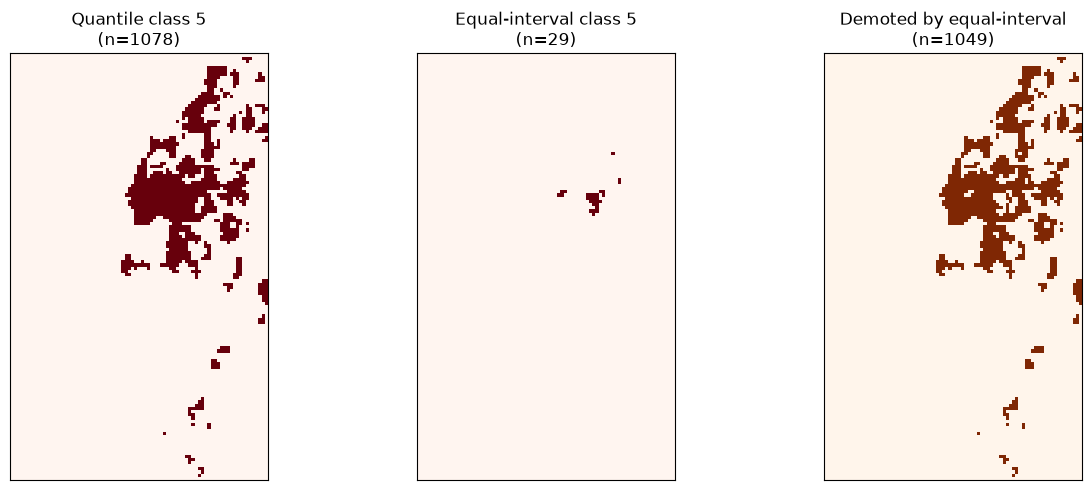

In [4]:
with __import__("rasterio").open(ROOT / "data" / "interim" / "grid_reference.tif") as ref:
    height, width = ref.height, ref.width

def to_grid(series_full):
    return series_full.to_numpy().reshape((height, width))

hei_full = hei.set_index("cell_id").reindex(range(height * width))
q5_mask = (hei_full["hei_class"] == 5).to_numpy().reshape((height, width))
eqint_class = pd.Series(np.nan, index=hei_full.index)
eqint_class.loc[v["cell_id"]] = v["hei_class_eqint"].to_numpy()
eqint5_mask = (eqint_class == 5).to_numpy().reshape((height, width))
demoted_mask = q5_mask & ~eqint5_mask

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
axes[0].imshow(q5_mask, cmap="Reds"); axes[0].set_title(f"Quantile class 5\n(n={q5_mask.sum()})")
axes[1].imshow(eqint5_mask, cmap="Reds"); axes[1].set_title(f"Equal-interval class 5\n(n={eqint5_mask.sum()})")
axes[2].imshow(demoted_mask, cmap="Oranges"); axes[2].set_title(f"Demoted by equal-interval\n(n={demoted_mask.sum()})")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

**This is the one place the design choice genuinely changes the story.** The quantile
class-5 footprint (left) covers most of the built-up urban core; equal-interval's class 5
(middle) shrinks to only the most extreme hot pixels, and the "demoted" cells (right) — which
the locked design calls top-quintile heat exposure but equal-interval wouldn't flag at all —
cover most of that same urban core. This happens because the HEI distribution is sharply
right-skewed (see the histogram in `04_final_figures.ipynb` / `hei_distribution_histogram.png`):
equal-width bins on a skewed variable put almost everything in one or two bins near the peak,
which is exactly why the plan chose quantile classification in the first place — not an
arbitrary preference, but a necessary choice given this data's shape.

## (c) Standardisation: robust (median/IQR) vs. standard (mean/std) z-score

Recomputing `lst_z` with a robust (median/IQR) estimator instead of mean/std, over the same
land cells, then propagating that through the same fixed HEI formula.

In [5]:
df = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
land = df[df["land_mask"] & df["lst"].notna()]
mean, std = land["lst"].mean(), land["lst"].std()
median = land["lst"].median()
q1, q3 = land["lst"].quantile(0.25), land["lst"].quantile(0.75)
iqr = q3 - q1
print(f"mean={mean:.3f}  median={median:.3f}  std={std:.3f}  iqr={iqr:.3f}")

v["robust_lst_z"] = (v["lst"] - median) / iqr
v["hei_raw_robust"] = v["robust_lst_z"] * v["pop_density"] * v["inv_ndvi"]
lo, hi = v["hei_raw_robust"].min(), v["hei_raw_robust"].max()
v["hei_robust"] = (v["hei_raw_robust"] - lo) / (hi - lo)

rho_c, p_c = stats.spearmanr(v["hei"], v["hei_robust"])
top10_robust = set(v.sort_values("hei_robust", ascending=False).head(10)["cell_id"])
overlap_c = len(baseline_top10 & top10_robust)

print(f"\nSpearman(hei_standard, hei_robust) = {rho_c:.4f}")
print(f"top-10 overlap: {overlap_c}/10")
print("robust top-10:", sorted(top10_robust))

mean=41.078  median=41.242  std=1.917  iqr=2.110

Spearman(hei_standard, hei_robust) = 0.9965
top-10 overlap: 10/10
robust top-10: [3303, 3618, 3619, 3700, 3701, 3781, 3782, 3862, 3863, 4024]


**Result: Spearman = 0.997, top-10 overlap = 10/10 (identical cells).** Unlike (a), this
isn't mathematically guaranteed — mean/std and median/IQR only produce identical rankings
when combined with `pop_density * inv_ndvi` if the underlying LST distribution is symmetric.
It's close to symmetric here (mean 41.08 vs median 41.24, a gap of 0.16°C against a ~1.9-2.1°C
spread), so the two z-scores end up nearly interchangeable — but this is an empirical fact
about *this* LST distribution, not a general guarantee. The exact same top-10 cells come out
on top either way.

## Conclusion

| Design choice | Alternative tested | Top-10 stable? | Class-5 pattern stable? |
|---|---|---|---|
| Normalisation (minmax) | rank-based | **Yes** — 10/10, Spearman=1.0 (guaranteed) | n/a |
| Standardisation (mean/std) | robust (median/IQR) | **Yes** — 10/10, Spearman=0.997 | n/a |
| Classification (quantile) | equal-interval | n/a | **No** — only 29/1,078 (2.7%) of class-5 cells agree |

**The top-10 hottest-and-densest-cell finding is robust**: two of the three variants tested
leave it completely unchanged, and the third (classification method) doesn't apply to a
top-10 ranking in the first place. That part of the paper's headline claim can be stated as a
robustness result.

**The class-5 ("high risk") spatial pattern is *not* robust to classification method** —
equal-interval classification would tell a materially different story, shrinking the
"high-risk" footprint from most of the urban core down to a handful of the most extreme
pixels. This isn't a flaw in the locked design (quantile classification is the right choice
for a right-skewed variable, and is explicitly what `config.yaml` specifies), but it does mean
the specific *shape* of the class-5 map is a property of the classification scheme as much as
the underlying data — worth a one-line caveat in the paper's methods section rather than
presenting the 5-class map as if the class boundaries were self-evident from the data alone.

**Flagging this explicitly, as requested**: finding (b) does change the story for the class-5
spatial pattern specifically (not the top-10 finding). Recommend a caveat sentence in the
paper rather than a redesign, since quantile classification remains the correct choice given
the skew — but wanted this surfaced before treating the 5-class map as unconditionally robust.